# Step 03: Separate Representation Training, Multi-Run Evaluation & Benchmark Export

Trains each representation model using 3-Fold Leave-One-Subject-Out (LOSO) cross-validation across multiple random seeds (`NUM_RUNS = 3`) to eliminate reliance on single-run chance.
Supports optional Weights & Biases (W&B) logging, evaluates out-of-fold test metrics (mean ± std), plots individual confusion matrices & metric breakdowns with error bars, automatically exports benchmark JSON/PNG artifacts, and presents a side-by-side comparative summary.


In [1]:
# Cell 1: System Imports & Multi-Run Setup
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
root_dir = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root_dir) not in sys.path: sys.path.insert(0, str(root_dir))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.train_loso import run_loso_cross_validation
from src.benchmark_eval import run_benchmark_evaluation

sns.set_theme(style="whitegrid")

# Multi-Run & Experiment Configuration
NUM_RUNS = 3      # Run 3 distinct random seeds (42, 52, 62) per representation to report mean ± std
USE_WANDB = False  # Set to True to log metrics to Weights & Biases
benchmark_results = {}
print(f"System ready for multi-run representation training (NUM_RUNS={NUM_RUNS}, USE_WANDB={USE_WANDB}).")


System ready for multi-run representation training (NUM_RUNS=3, USE_WANDB=False).



>>> Training Representation 1 (REP1_DOPPLER) <<<

Starting LOSO Cross-Validation for Representation: rep1_doppler
Runs: 3 | Seeds: [42, 52, 62] | Epochs: 20 | LR: 0.0005 | Batch Size: 32

>>> Starting Run 1/3 (Seed: 42) <<<
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/20] Train Loss: 0.5520, Train Acc: 69.71%
  Epoch [10/20] Train Loss: 0.4301, Train Acc: 80.77%
  Epoch [15/20] Train Loss: 0.3396, Train Acc: 83.65%
  Epoch [20/20] Train Loss: 0.4217, Train Acc: 82.69%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/20] Train Loss: 0.5962, Train Acc: 68.20%
  Epoch [10/20] Train Loss: 0.4689, Train Acc: 80.18%
  Epoch [15/20] Train Loss: 0.3126, Train Acc: 85.25%
  Epoch [20/20] Train Loss: 0.4247, Train Acc: 80.65%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/20] Train Loss: 0.5242, Train Acc: 72.56%
  Epoch [10/2

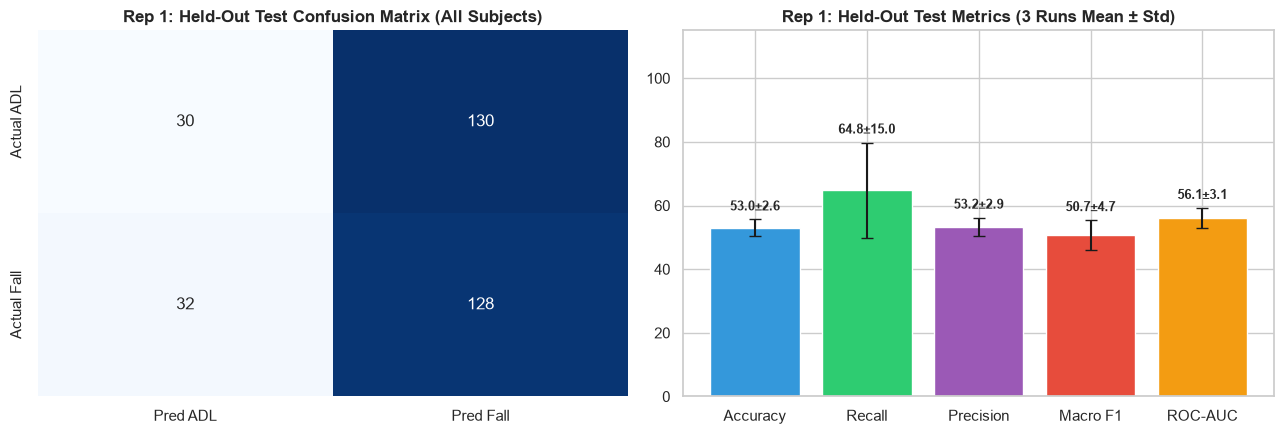

Saved Rep 1 benchmark plot image to: models\benchmarks\rep1_doppler_benchmark.png


In [2]:
# Cell 2: Train & Evaluate Representation 1 (Micro-Doppler Time Map - ResNet-18)
rep1_key = "rep1_doppler"
print(f"\n>>> Training Representation 1 ({rep1_key.upper()}) <<<")
res1 = run_loso_cross_validation(rep_key=rep1_key, epochs=20, lr=5e-4, batch_size=32, num_runs=NUM_RUNS, use_wandb=USE_WANDB, save_benchmark=True)
benchmark_results[rep1_key] = res1

# Plot & Save Out-of-Fold Test Metrics for Representation 1 (Mean ± Std)
test_m1 = res1["test_metrics"]
cm_test1 = np.array(test_m1["confusion_matrix"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=100)
sns.heatmap(cm_test1, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Pred ADL", "Pred Fall"], yticklabels=["Actual ADL", "Actual Fall"])
axes[0].set_title(f"Rep 1: Held-Out Test Confusion Matrix (All Subjects)", fontweight="bold")

m_names = ["Accuracy", "Recall", "Precision", "Macro F1", "ROC-AUC"]
m_vals1 = [test_m1["accuracy"]*100, test_m1["recall"]*100, test_m1["precision"]*100, test_m1["macro_f1"]*100, test_m1["roc_auc"]*100]
m_stds1 = [test_m1["accuracy_std"]*100, test_m1["recall_std"]*100, test_m1["precision_std"]*100, test_m1["macro_f1_std"]*100, test_m1["roc_auc_std"]*100]
bars1_t = axes[1].bar(m_names, m_vals1, yerr=m_stds1, capsize=4, color=["#3498db", "#2ecc71", "#9b59b6", "#e74c3c", "#f39c12"])
axes[1].set_ylim(0, 115)
axes[1].set_title(f"Rep 1: Held-Out Test Metrics ({NUM_RUNS} Runs Mean ± Std)", fontweight="bold")
for bar, std in zip(bars1_t, m_stds1):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., h + std + 2, f"{h:.1f}±{std:.1f}", ha="center", va="bottom", fontweight="bold", fontsize=9)

plt.tight_layout()
rep1_img_path = Path("models/benchmarks/rep1_doppler_benchmark.png")
plt.savefig(rep1_img_path, dpi=300)
plt.show()
print(f"Saved Rep 1 benchmark plot image to: {rep1_img_path}")



>>> Training Representation 2 (REP2_PROJECTIONS) <<<

Starting LOSO Cross-Validation for Representation: rep2_projections
Runs: 3 | Seeds: [42, 52, 62] | Epochs: 20 | LR: 0.0005 | Batch Size: 32

>>> Starting Run 1/3 (Seed: 42) <<<
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/20] Train Loss: 0.0133, Train Acc: 99.52%
  Epoch [10/20] Train Loss: 0.0034, Train Acc: 100.00%
  Epoch [15/20] Train Loss: 0.0041, Train Acc: 100.00%
  Epoch [20/20] Train Loss: 0.0053, Train Acc: 100.00%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/20] Train Loss: 0.0077, Train Acc: 100.00%
  Epoch [10/20] Train Loss: 0.0149, Train Acc: 99.54%
  Epoch [15/20] Train Loss: 0.0208, Train Acc: 99.54%
  Epoch [20/20] Train Loss: 0.0225, Train Acc: 99.54%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/20] Train Loss: 0.0141, Train Acc: 99.53%
 

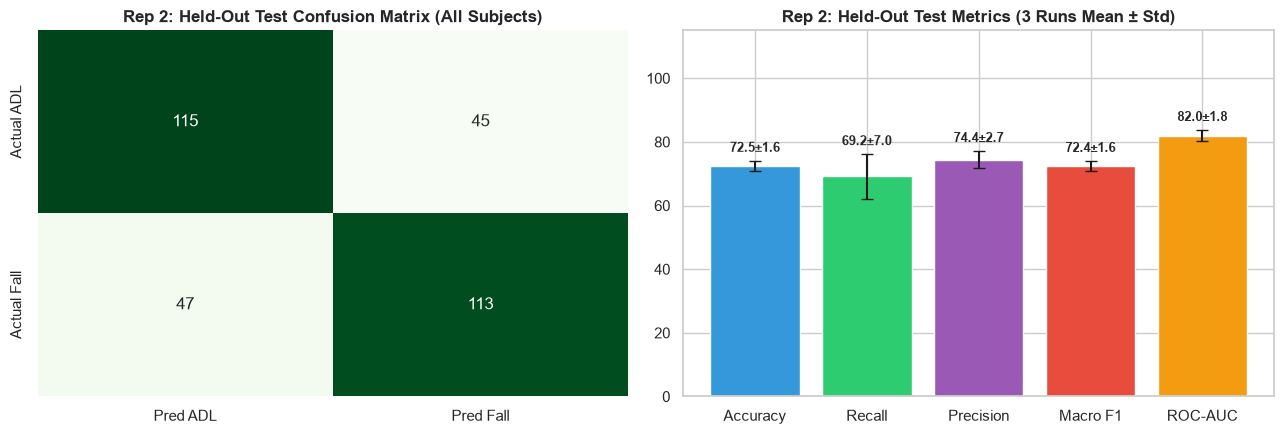

Saved Rep 2 benchmark plot image to: models\benchmarks\rep2_projections_benchmark.png


In [3]:
# Cell 3: Train & Evaluate Representation 2 (Spatial 2D Orthogonal Projections - ResNet-18)
rep2_key = "rep2_projections"
print(f"\n>>> Training Representation 2 ({rep2_key.upper()}) <<<")
res2 = run_loso_cross_validation(rep_key=rep2_key, epochs=20, lr=5e-4, batch_size=32, num_runs=NUM_RUNS, use_wandb=USE_WANDB, save_benchmark=True)
benchmark_results[rep2_key] = res2

# Plot & Save Out-of-Fold Test Metrics for Representation 2 (Mean ± Std)
test_m2 = res2["test_metrics"]
cm_test2 = np.array(test_m2["confusion_matrix"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=100)
sns.heatmap(cm_test2, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[0],
            xticklabels=["Pred ADL", "Pred Fall"], yticklabels=["Actual ADL", "Actual Fall"])
axes[0].set_title(f"Rep 2: Held-Out Test Confusion Matrix (All Subjects)", fontweight="bold")

m_vals2 = [test_m2["accuracy"]*100, test_m2["recall"]*100, test_m2["precision"]*100, test_m2["macro_f1"]*100, test_m2["roc_auc"]*100]
m_stds2 = [test_m2["accuracy_std"]*100, test_m2["recall_std"]*100, test_m2["precision_std"]*100, test_m2["macro_f1_std"]*100, test_m2["roc_auc_std"]*100]
bars2_t = axes[1].bar(m_names, m_vals2, yerr=m_stds2, capsize=4, color=["#3498db", "#2ecc71", "#9b59b6", "#e74c3c", "#f39c12"])
axes[1].set_ylim(0, 115)
axes[1].set_title(f"Rep 2: Held-Out Test Metrics ({NUM_RUNS} Runs Mean ± Std)", fontweight="bold")
for bar, std in zip(bars2_t, m_stds2):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., h + std + 2, f"{h:.1f}±{std:.1f}", ha="center", va="bottom", fontweight="bold", fontsize=9)

plt.tight_layout()
rep2_img_path = Path("models/benchmarks/rep2_projections_benchmark.png")
plt.savefig(rep2_img_path, dpi=300)
plt.show()
print(f"Saved Rep 2 benchmark plot image to: {rep2_img_path}")



>>> Training Representation 3 (REP3_POINTSET) <<<

Starting LOSO Cross-Validation for Representation: rep3_pointset
Runs: 3 | Seeds: [42, 52, 62] | Epochs: 20 | LR: 0.0005 | Batch Size: 32

>>> Starting Run 1/3 (Seed: 42) <<<
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/20] Train Loss: 0.2061, Train Acc: 97.12%
  Epoch [10/20] Train Loss: 0.0352, Train Acc: 100.00%
  Epoch [15/20] Train Loss: 0.0144, Train Acc: 99.52%
  Epoch [20/20] Train Loss: 0.0035, Train Acc: 100.00%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/20] Train Loss: 0.2579, Train Acc: 94.01%
  Epoch [10/20] Train Loss: 0.0299, Train Acc: 99.54%
  Epoch [15/20] Train Loss: 0.0389, Train Acc: 99.08%
  Epoch [20/20] Train Loss: 0.0060, Train Acc: 100.00%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/20] Train Loss: 0.2726, Train Acc: 93.02%
  Epoch 

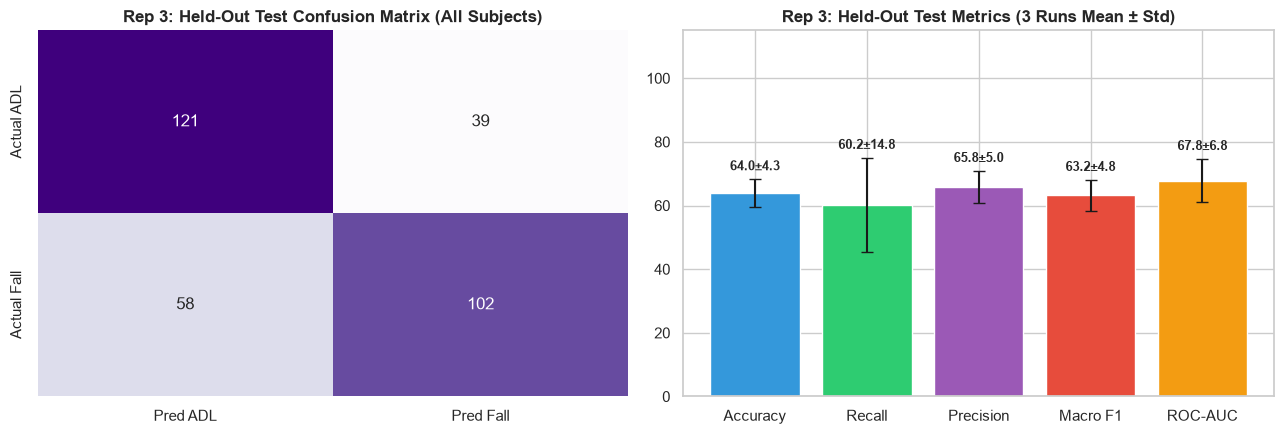

Saved Rep 3 benchmark plot image to: models\benchmarks\rep3_pointset_benchmark.png


In [4]:
# Cell 4: Train & Evaluate Representation 3 (Native 3D Point Set - PointNet++)
rep3_key = "rep3_pointset"
print(f"\n>>> Training Representation 3 ({rep3_key.upper()}) <<<")
res3 = run_loso_cross_validation(rep_key=rep3_key, epochs=20, lr=5e-4, batch_size=32, num_runs=NUM_RUNS, use_wandb=USE_WANDB, save_benchmark=True)
benchmark_results[rep3_key] = res3

# Plot & Save Out-of-Fold Test Metrics for Representation 3 (Mean ± Std)
test_m3 = res3["test_metrics"]
cm_test3 = np.array(test_m3["confusion_matrix"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=100)
sns.heatmap(cm_test3, annot=True, fmt="d", cmap="Purples", cbar=False, ax=axes[0],
            xticklabels=["Pred ADL", "Pred Fall"], yticklabels=["Actual ADL", "Actual Fall"])
axes[0].set_title(f"Rep 3: Held-Out Test Confusion Matrix (All Subjects)", fontweight="bold")

m_vals3 = [test_m3["accuracy"]*100, test_m3["recall"]*100, test_m3["precision"]*100, test_m3["macro_f1"]*100, test_m3["roc_auc"]*100]
m_stds3 = [test_m3["accuracy_std"]*100, test_m3["recall_std"]*100, test_m3["precision_std"]*100, test_m3["macro_f1_std"]*100, test_m3["roc_auc_std"]*100]
bars3_t = axes[1].bar(m_names, m_vals3, yerr=m_stds3, capsize=4, color=["#3498db", "#2ecc71", "#9b59b6", "#e74c3c", "#f39c12"])
axes[1].set_ylim(0, 115)
axes[1].set_title(f"Rep 3: Held-Out Test Metrics ({NUM_RUNS} Runs Mean ± Std)", fontweight="bold")
for bar, std in zip(bars3_t, m_stds3):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., h + std + 2, f"{h:.1f}±{std:.1f}", ha="center", va="bottom", fontweight="bold", fontsize=9)

plt.tight_layout()
rep3_img_path = Path("models/benchmarks/rep3_pointset_benchmark.png")
plt.savefig(rep3_img_path, dpi=300)
plt.show()
print(f"Saved Rep 3 benchmark plot image to: {rep3_img_path}")


Saved master benchmark summary JSON to: models\benchmarks\loso_benchmark_results.json

      TI mmWave Radar Fall Detection: Representation Benchmark Summary
| Representation                               |   Accuracy (%) |   Precision (%) |   Recall (%) |   Macro F1 (%) |   ROC-AUC |   False Alarm Rate / FPR (%) |   Latency (ms/seq) |
|:---------------------------------------------|---------------:|----------------:|-------------:|---------------:|----------:|-----------------------------:|-------------------:|
| Rep 1: Doppler-Time Map (ResNet-18)          |          53.02 |           53.25 |        64.79 |          50.71 |    0.5612 |                        58.75 |              12.79 |
| Rep 2: 2D Orthogonal Projections (ResNet-18) |          72.5  |           74.41 |        69.17 |          72.37 |    0.8196 |                        24.17 |              11.59 |
| Rep 3: Native 3D Point Tensor (PointNet++)   |          63.96 |           65.81 |        60.21 |          63.2  |    0.6

C:\Users\joeyw\AppData\Local\Temp\ipykernel_27632\2676755762.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(df_plot["Rep Label"], rotation=15)
C:\Users\joeyw\AppData\Local\Temp\ipykernel_27632\2676755762.py:47: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[2].set_xticklabels(df_plot["Rep Label"], rotation=15)


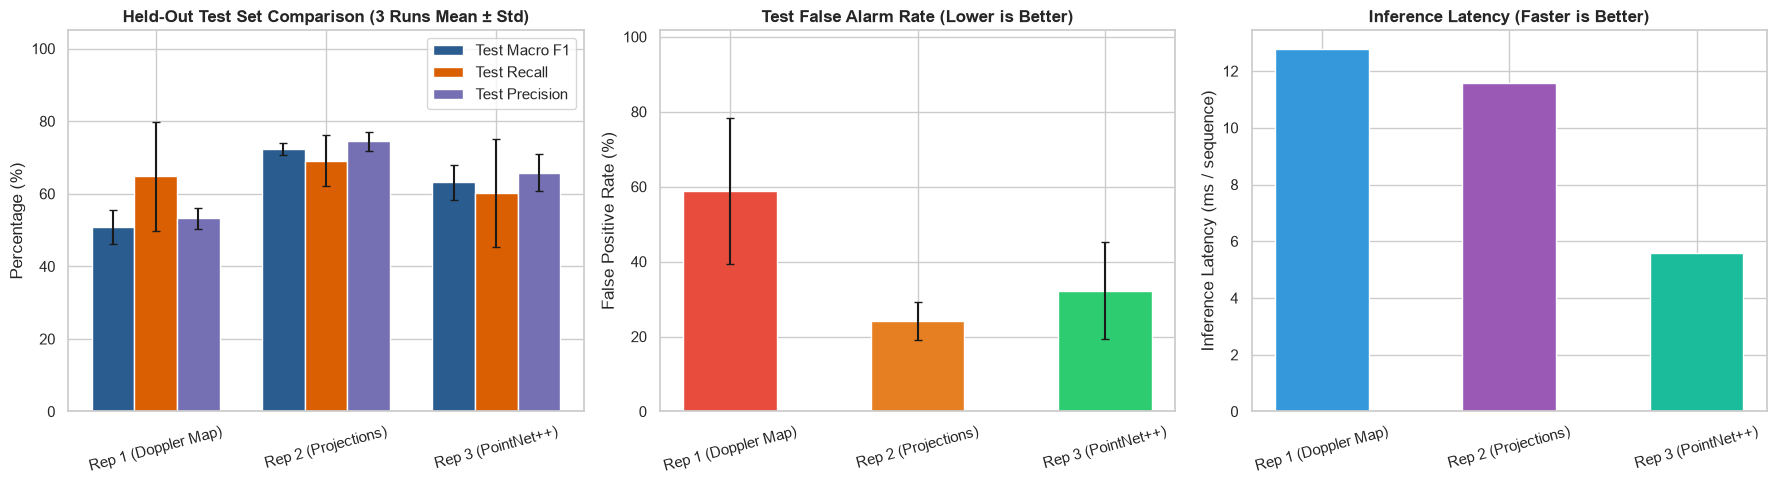

Saved final benchmark comparison plot image to: models\benchmarks\representation_benchmark_comparison.png


In [5]:
# Cell 5: Side-by-Side Representation Benchmark Comparison (Bottom Summary)
json_out_path = Path("models/benchmarks/loso_benchmark_results.json")
json_out_path.parent.mkdir(parents=True, exist_ok=True)
with open(json_out_path, "w", encoding="utf-8") as f:
    json.dump(benchmark_results, f, indent=4)
print(f"Saved master benchmark summary JSON to: {json_out_path}")

df_summary = run_benchmark_evaluation(json_out_path)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=100)
df_plot = df_summary.copy()
df_plot["Rep Label"] = ["Rep 1 (Doppler Map)", "Rep 2 (Projections)", "Rep 3 (PointNet++)"]
x_axis = np.arange(len(df_plot))
width = 0.25

# Extract Test metrics & stds for bottom summary comparison
test_f1 = [res1["test_metrics"]["macro_f1"]*100, res2["test_metrics"]["macro_f1"]*100, res3["test_metrics"]["macro_f1"]*100]
test_f1_std = [res1["test_metrics"]["macro_f1_std"]*100, res2["test_metrics"]["macro_f1_std"]*100, res3["test_metrics"]["macro_f1_std"]*100]

test_rec = [res1["test_metrics"]["recall"]*100, res2["test_metrics"]["recall"]*100, res3["test_metrics"]["recall"]*100]
test_rec_std = [res1["test_metrics"]["recall_std"]*100, res2["test_metrics"]["recall_std"]*100, res3["test_metrics"]["recall_std"]*100]

test_prec = [res1["test_metrics"]["precision"]*100, res2["test_metrics"]["precision"]*100, res3["test_metrics"]["precision"]*100]
test_prec_std = [res1["test_metrics"]["precision_std"]*100, res2["test_metrics"]["precision_std"]*100, res3["test_metrics"]["precision_std"]*100]

axes[0].bar(x_axis - width, test_f1, yerr=test_f1_std, capsize=3, width=width, label="Test Macro F1", color='#2b5c8f')
axes[0].bar(x_axis, test_rec, yerr=test_rec_std, capsize=3, width=width, label="Test Recall", color='#d95f02')
axes[0].bar(x_axis + width, test_prec, yerr=test_prec_std, capsize=3, width=width, label="Test Precision", color='#7570b3')
axes[0].set_xticks(x_axis)
axes[0].set_xticklabels(df_plot["Rep Label"], rotation=15)
axes[0].set_ylabel("Percentage (%)")
axes[0].set_title(f"Held-Out Test Set Comparison ({NUM_RUNS} Runs Mean ± Std)", fontweight='bold')
axes[0].legend()
axes[0].set_ylim([0, 105])

test_fpr = [res1["test_metrics"]["fpr"]*100, res2["test_metrics"]["fpr"]*100, res3["test_metrics"]["fpr"]*100]
test_fpr_std = [res1["test_metrics"]["fpr_std"]*100, res2["test_metrics"]["fpr_std"]*100, res3["test_metrics"]["fpr_std"]*100]
axes[1].bar(df_plot["Rep Label"], test_fpr, yerr=test_fpr_std, capsize=3, color=['#e74c3c', '#e67e22', '#2ecc71'], width=0.5)
axes[1].set_ylabel("False Positive Rate (%)")
axes[1].set_title("Test False Alarm Rate (Lower is Better)", fontweight='bold')
axes[1].set_xticklabels(df_plot["Rep Label"], rotation=15)
axes[1].set_ylim([0, max(max([a + b for a, b in zip(test_fpr, test_fpr_std)]) * 1.3, 10.0)])

axes[2].bar(df_plot["Rep Label"], df_plot["Latency (ms/seq)"], color=['#3498db', '#9b59b6', '#1abc9c'], width=0.5)
axes[2].set_ylabel("Inference Latency (ms / sequence)")
axes[2].set_title("Inference Latency (Faster is Better)", fontweight='bold')
axes[2].set_xticklabels(df_plot["Rep Label"], rotation=15)

plt.tight_layout()
cmp_fig_path = Path("models/benchmarks/representation_benchmark_comparison.png")
plt.savefig(cmp_fig_path, dpi=300)
plt.show()
print(f"Saved final benchmark comparison plot image to: {cmp_fig_path}")
